# Local Field Potential Analysis

This tutorial covers the LFP tools of `braintools.metric`: generating an LFP from spikes, and the spectral, coupling, and laminar analyses. Each analysis is first checked on a synthetic signal whose answer is known.

| Function | Purpose |
|---|---|
| `unitary_LFP(times, spikes, spike_type, location=...)` | kernel-based LFP contribution of an excitatory or inhibitory population |
| `power_spectral_density(lfp, dt, nperseg=None, ...)` | Welch power spectrum |
| `coherence_analysis(x, y, dt, nperseg=None, ...)` | magnitude-squared coherence (Welch) |
| `spectral_entropy(lfp, dt, freq_range=(1, 100))` | normalized entropy of the spectrum, 0 (one peak) to 1 (flat) |
| `phase_amplitude_coupling(lfp, dt, phase_freq_range, amplitude_freq_range, n_bins=18)` | Tort modulation index |
| `theta_gamma_coupling(lfp, dt)` | the same with 4-8 Hz phase and 30-80 Hz amplitude |
| `lfp_phase_coherence(signals, dt, freq_band)` | pairwise phase-locking value between channels in a band |
| `current_source_density(lfp_laminar, electrode_spacing)` | second spatial difference of a laminar recording |

For the spectral functions, `dt` is the sampling interval: a plain number is in **seconds**, and a quantity is converted. `unitary_LFP` takes `times` in milliseconds.

## 1. Setup

In [1]:
import brainunit as u
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

import braintools.metric as bm

rng = np.random.default_rng(0)

## 2. An LFP from Spiking Activity

`unitary_LFP` places the neurons of a population at random in a 0.2 mm x 0.2 mm area around the electrode. Each spike adds a Gaussian waveform whose amplitude decays with distance and whose delay grows with distance (axonal conduction). The amplitude and sign of the excitatory and inhibitory contributions depend on the recording `location` (`'soma layer'`, `'deep layer'`, `'superficial layer'`, `'surface layer'`).

Below, 200 excitatory and 50 inhibitory neurons fire with a rate modulated at 8 Hz (theta) for 10 s.

superficial layer: correlation of E and I contributions -0.79


soma layer       : correlation of E and I contributions +0.79


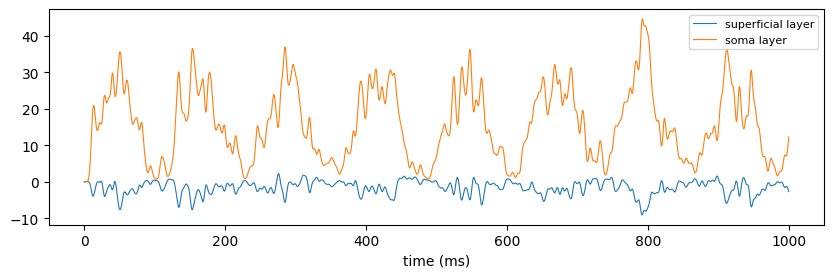

In [2]:
dt_ms = 0.5
T = int(10_000 / dt_ms)
t_ms = np.arange(T) * dt_ms
rate = 10 * (1 + 0.8 * np.sin(2 * np.pi * 8 * t_ms / 1000))  # Hz
exc = (rng.random((T, 200)) < (rate * dt_ms * 1e-3)[:, None]).astype(float)
inh = (rng.random((T, 50)) < (2 * rate * dt_ms * 1e-3)[:, None]).astype(float)

lfps = {}
for location in ["superficial layer", "soma layer"]:
    e = np.asarray(bm.unitary_LFP(t_ms, exc, "exc", location=location, seed=0))
    i = np.asarray(bm.unitary_LFP(t_ms, inh, "inh", location=location, seed=0))
    lfps[location] = e + i
    print(f"{location:17s}: correlation of E and I contributions {np.corrcoef(e, i)[0, 1]:+.2f}")

fig, ax = plt.subplots(figsize=(10, 2.8))
for location, x in lfps.items():
    ax.plot(t_ms[:2000], x[:2000], lw=0.8, label=location)
ax.set_xlabel("time (ms)")
ax.legend(fontsize=8)
plt.show()

lfp = lfps["soma layer"]
dt = dt_ms * u.ms

## 3. Power Spectrum and Frequency Resolution

`power_spectral_density` uses Welch's method: the signal is cut into Hann-windowed segments of `nperseg` samples with 50 % overlap, and their periodograms are averaged. The frequency resolution is $1 / (\texttt{nperseg} \cdot dt)$. The default `nperseg = n_time // 8` is fine for long recordings but too coarse for short ones, so set it from the resolution you need: 2 s segments give 0.5 Hz bins.

The result equals `scipy.signal.welch` with the same (symmetric) Hann window and `detrend=False`; scipy's defaults differ slightly (a periodic window and mean detrending).

resolution 0.50 Hz; max relative difference from scipy 9.1e-08
spectral peak at 8.0 Hz (rate modulation 8 Hz)
  delta    0.9 % of 1-100 Hz power
  theta   86.6 % of 1-100 Hz power
  beta     4.4 % of 1-100 Hz power
  gamma    8.1 % of 1-100 Hz power


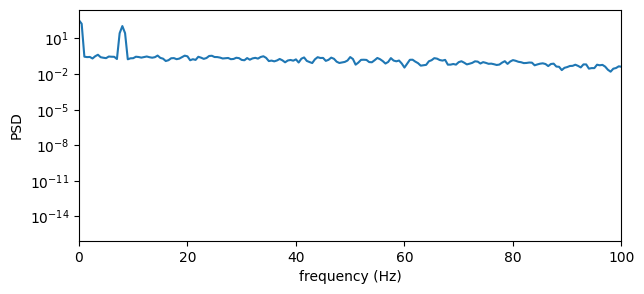

In [3]:
from scipy import signal as sps

freqs, psd = bm.power_spectral_density(lfp, dt, nperseg=4000)
f_ref, p_ref = sps.welch(lfp, fs=1000 / dt_ms, window=np.hanning(4000), nperseg=4000, detrend=False)
print(f"resolution {float(freqs[1]):.2f} Hz; max relative difference from scipy {np.max(np.abs(np.asarray(psd) - p_ref)) / p_ref.max():.1e}")
print(f"spectral peak at {float(freqs[np.argmax(np.asarray(psd)[2:]) + 2]):.1f} Hz (rate modulation 8 Hz)")


def band_power(freqs, psd, lo, hi):
    f, p = np.asarray(freqs), np.asarray(psd)
    m = (f >= lo) & (f < hi)
    return p[m].sum() * (f[1] - f[0])


total = band_power(freqs, psd, 1, 100)
for name, (lo, hi) in {"delta": (1, 4), "theta": (4, 12), "beta": (12, 30), "gamma": (30, 100)}.items():
    print(f"  {name:6s} {100 * band_power(freqs, psd, lo, hi) / total:5.1f} % of 1-100 Hz power")

fig, ax = plt.subplots(figsize=(7, 3))
ax.semilogy(freqs, psd)
ax.set_xlim(0, 100)
ax.set_xlabel("frequency (Hz)")
ax.set_ylabel("PSD")
plt.show()

## 4. Coherence

`coherence_analysis` estimates $C_{xy}(f) = \lvert\langle P_{xy}\rangle\rvert^2 / (\langle P_{xx}\rangle\langle P_{yy}\rangle)$ by averaging over Welch segments; with a single segment it would be 1 everywhere, so make sure many segments fit. For two signals that share a component $s$ plus independent noise of equal power, $x = s + n_1$, $y = s + n_2$, the true coherence is $\left(S / (S + N)\right)^2$ , where $S$ and $N$ are the signal and noise spectra. The Welch estimate is biased upward by roughly $(1 - C)/K$ for $K$ averaged segments, which matters where the true coherence is small.

In [4]:
fs = 1000.0
n = 60_000
shared = np.sin(2 * np.pi * 10 * np.arange(n) / fs) + rng.normal(size=n) * 0.5
x = shared + rng.normal(size=n)
y = shared + rng.normal(size=n)
f, coh = bm.coherence_analysis(x, y, 1 / fs, nperseg=2000)
f, coh = np.asarray(f), np.asarray(coh)

S_noise = 0.25 / (fs / 2)  # one-sided PSD of the shared white noise (variance 0.25)
N = 1.0 / (fs / 2)  # one-sided PSD of each private noise (variance 1)
print(f"coherence at 10 Hz (shared sinusoid): {coh[np.argmin(np.abs(f - 10))]:.3f}")
K = 2 * n // 2000 - 1  # number of 50 %-overlapping segments
C = (S_noise / (S_noise + N)) ** 2
print(f"coherence elsewhere (shared noise only): mean {coh[(f > 20) & (f < 400)].mean():.3f}; "
      f"true value {C:.3f}, plus estimator bias (1 - C)/K = {(1 - C) / K:.3f} -> {C + (1 - C) / K:.3f}")

coherence at 10 Hz (shared sinusoid): 0.994
coherence elsewhere (shared noise only): mean 0.061; true value 0.040, plus estimator bias (1 - C)/K = 0.016 -> 0.056


## 5. Spectral Entropy

`spectral_entropy` normalizes the power spectrum in `freq_range` to a probability distribution and returns its Shannon entropy divided by the maximum (log of the number of bins): close to 1 for white noise and close to 0 for a single sharp peak.

In [5]:
t = np.arange(20_000) / fs
signals = {
    "white noise": rng.normal(size=t.size),
    "10 Hz sine + 1% noise": np.sin(2 * np.pi * 10 * t) + 0.01 * rng.normal(size=t.size),
    "simulated LFP": None,
}
for name, sig in signals.items():
    h = bm.spectral_entropy(lfp, dt) if sig is None else bm.spectral_entropy(sig, 1 / fs)
    print(f"{name:22s} spectral entropy {float(h):.3f}")

white noise            spectral entropy 0.994
10 Hz sine + 1% noise  spectral entropy 0.158


simulated LFP          spectral entropy 0.380


## 6. Phase-Amplitude Coupling

`phase_amplitude_coupling` extracts the phase of a slow band and the amplitude envelope of a fast band (analytic signals via an FFT band-pass), averages the amplitude in `n_bins` phase bins, and returns Tort's modulation index: the Kullback-Leibler divergence of that amplitude distribution from uniform, divided by $\log(\texttt{n\_bins})$. It also returns the bin centres and mean amplitudes.

The index is small in practice: even strong coupling gives values of a few hundredths. Calibrate it with synthetic signals before interpreting a measurement. Here theta (6 Hz) modulates the amplitude of a 60 Hz oscillation with depth $k$:

 depth k        MI  theta_gamma_coupling


     0.0   0.00003               0.00006
     0.2   0.00339               0.00320
     0.5   0.02195               0.02066
     0.9   0.07078               0.06335


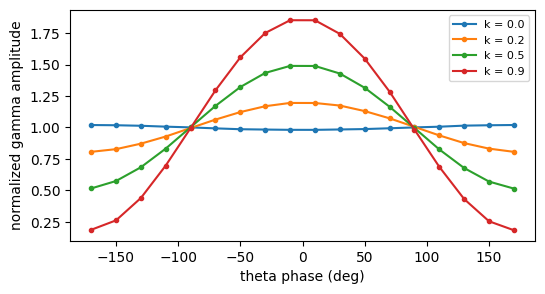

simulated LFP: MI 0.01374


In [6]:
t = np.arange(20_000) / fs
theta = np.sin(2 * np.pi * 6 * t)
print(f"{'depth k':>8s} {'MI':>9s} {'theta_gamma_coupling':>21s}")
results = {}
for k in [0.0, 0.2, 0.5, 0.9]:
    sig = theta + (1 + k * theta) * 0.5 * np.sin(2 * np.pi * 60 * t) + 0.3 * rng.normal(size=t.size)
    mi, bins, amps = bm.phase_amplitude_coupling(sig, 1 / fs, phase_freq_range=(4, 8), amplitude_freq_range=(50, 70))
    results[k] = (bins, amps)
    print(f"{k:8.1f} {float(mi):9.5f} {float(bm.theta_gamma_coupling(sig, 1 / fs)):21.5f}")

fig, ax = plt.subplots(figsize=(6, 3))
for k, (bins, amps) in results.items():
    ax.plot(np.degrees(bins), np.asarray(amps) / np.mean(amps), "o-", ms=3, label=f"k = {k}")
ax.set_xlabel("theta phase (deg)")
ax.set_ylabel("normalized gamma amplitude")
ax.legend(fontsize=8)
plt.show()

mi_lfp, _, _ = bm.phase_amplitude_coupling(lfp, dt)
print(f"simulated LFP: MI {float(mi_lfp):.5f}")

For no coupling the index is close to 0 but not exactly 0 (finite data); compare with surrogates, for example by shifting the amplitude series relative to the phase series, to judge significance. The simulated LFP has no gamma *rhythm*, yet its index is clearly non-zero: the spike waveforms contribute broadband high-frequency power, and that power rises and falls with the theta-modulated firing rate. This is genuine phase-amplitude coupling, which is why a non-zero index alone does not prove a nested oscillation.

## 7. Phase Coherence Across Channels

`lfp_phase_coherence(signals, dt, freq_band)` band-passes every channel, takes its instantaneous phase, and returns the matrix of pairwise phase-locking values $\lvert\langle e^{i(\phi_i - \phi_j)}\rangle_t\rvert$, which is 1 for a constant phase difference regardless of its value. Channels that carry no power in the band are reported as 0 rather than an arbitrary phase.

In [7]:
alpha = np.sin(2 * np.pi * 10 * t)
channels = np.stack([
    alpha + 0.5 * rng.normal(size=t.size),
    np.roll(alpha, 25) + 0.5 * rng.normal(size=t.size),  # 90 degree lag at 10 Hz
    -alpha + 0.5 * rng.normal(size=t.size),  # anti-phase
    rng.normal(size=t.size),  # unrelated
], axis=1)
plv = np.asarray(bm.lfp_phase_coherence(channels, 1 / fs, freq_band=(8, 12)))
print(np.round(plv, 3))

[[1.    0.998 0.998 0.076]
 [0.998 1.    0.998 0.076]
 [0.998 0.998 1.    0.081]
 [0.076 0.076 0.081 1.   ]]


Channels 0-2 lock to each other at different but constant phase differences (0, 90 and 180 degrees) and all give a PLV near 1. The unrelated channel is low but not 0: for independent signals the PLV has a finite-data floor of roughly $1/\sqrt{\text{duration} \times \text{bandwidth}}$ (here $1/\sqrt{20\,\text{s} \times 4\,\text{Hz}} \approx 0.1$).

## 8. Current Source Density

For a laminar recording with electrode spacing $h$, `current_source_density` returns

$$\text{CSD}_k = -\sigma\,\frac{V_{k+1} - 2V_k + V_{k-1}}{h^2},$$

the negative second spatial difference along the electrode axis (the last axis by default), scaled by the conductivity `conductivity` (default 1). The two boundary electrodes are dropped. **Negative CSD is a current sink** and positive a source. A potential trough at a depth therefore appears as a sink flanked by sources:

CSD shape (200, 18) (two boundary electrodes dropped)
at the trough depth: CSD -141.9, analytic -V'' -156.2


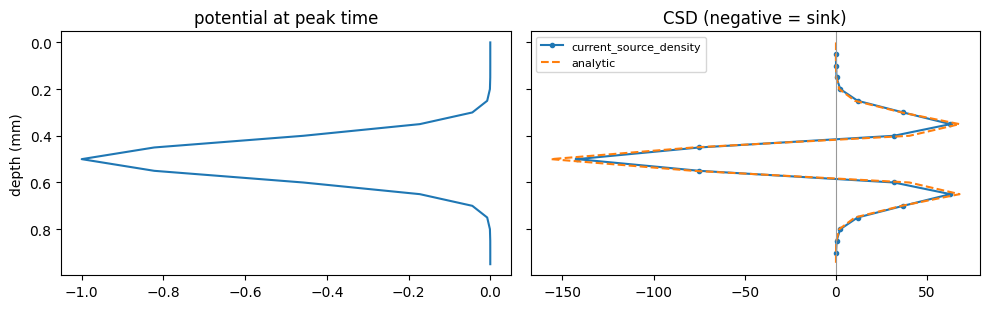

In [8]:
h = 0.05  # mm
depth = np.arange(20) * h
z0, s = 0.5, 0.08
profile = -np.exp(-(depth - z0) ** 2 / (2 * s ** 2))  # a potential trough at 0.5 mm
V = profile[None, :] * np.sin(2 * np.pi * 8 * t[:200])[:, None]  # (time, electrodes), oscillating amplitude

csd = np.asarray(bm.current_source_density(V, h))
exact = -(np.exp(-(depth - z0) ** 2 / (2 * s ** 2)) * ((depth - z0) ** 2 / s ** 4 - 1 / s ** 2)) * -1  # -d2V/dz2
print(f"CSD shape {csd.shape} (two boundary electrodes dropped)")
peak = np.argmax(np.abs(V).max(axis=1))
print(f"at the trough depth: CSD {csd[peak, 9]:.1f}, analytic -V'' {exact[10] * np.sin(2 * np.pi * 8 * t[peak]):.1f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
axes[0].plot(V[peak], depth)
axes[0].set_title("potential at peak time")
axes[0].set_ylabel("depth (mm)")
axes[1].plot(csd[peak], depth[1:-1], "o-", ms=3, label="current_source_density")
axes[1].plot(exact * np.sin(2 * np.pi * 8 * t[peak]), depth, "--", label="analytic")
axes[1].axvline(0, color="0.6", lw=0.8)
axes[1].set_title("CSD (negative = sink)")
axes[1].legend(fontsize=8)
axes[0].invert_yaxis()
fig.tight_layout()
plt.show()

The 3-point difference slightly underestimates the analytic second derivative when the spacing is not small compared with the width of the profile (here $h = 0.05$ mm against $\sigma = 0.08$ mm).

## Summary

- `unitary_LFP` turns population spikes into an LFP whose shape depends on the recording location.
- Choose `nperseg` from the frequency resolution you need ($1/(\texttt{nperseg}\cdot dt)$); the default is too coarse for short recordings. Results equal `scipy.signal.welch` / `coherence` with the same window and no detrending.
- Coherence needs many segments; spectral entropy runs from 0 (peaked) to 1 (flat).
- Tort's modulation index is small even for strong coupling: calibrate with synthetic signals and test against surrogates.
- `lfp_phase_coherence` is a phase-locking value in a band; `current_source_density` is $-\sigma\,\partial^2 V/\partial z^2$ with sinks negative.